# LAB 3B : Train a decision tree classifier using scikit-learn and visualize the tree. Analyze performance with/without pruning and depth control. Demonstrate overfitting using synthetic data.

# Banknote Authentication: Decision Tree Classification & Overfitting Analysis


## Objective

Train a Decision Tree Classifier using the Bill Authentication dataset and:

- Preprocess and explore the dataset.
- Split the data into training and testing sets.
- Train a Decision Tree Classifier without pruning.
- Visualize the decision tree.
- Analyze the effect of controlling tree depth.
- Apply cost-complexity pruning.
- Compare model performance with and without pruning.
- Demonstrate overfitting using synthetic data.

## Dataset

The dataset contains features extracted from banknote images:

- Variance
- Skewness
- Curtosis
- Entropy

The target variable is:

- Class = 0 → Genuine banknote
- Class = 1 → Forged banknote

## Import Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

## import Dataset

In [3]:
df =  pd.read_csv(r'C:\Users\omm91\Downloads\Breast_Cancer_Wisconsin.csv')

## EDA Steps

In [4]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [5]:
# Display dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display column names
print("\nColumns:")
print(df.columns.tolist())

Number of rows: 569
Number of columns: 33

Columns:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']


In [6]:
# Dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

In [7]:
# Statistical summary
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


In [8]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

Missing values:
id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst

In [11]:
print(df.columns)

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='str')


In [12]:
# Check class distribution
print(df["diagnosis"].value_counts())

diagnosis
B    357
M    212
Name: count, dtype: int64


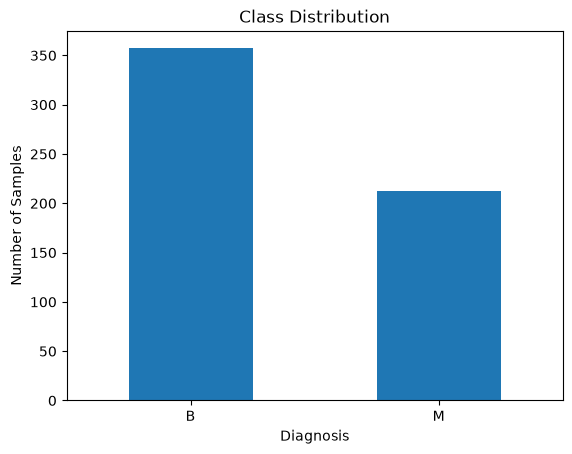

In [13]:
# Visualization of class distribution
df["diagnosis"].value_counts().plot(kind="bar")

plt.title("Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.show()

## Dataset Exploration

The dataset contains 1,372 observations and 5 columns.

The four predictor variables are:

1. Variance
2. Skewness
3. Curtosis
4. Entropy

The `Class` column is the target variable.

A Decision Tree does not require feature scaling because it makes decisions using
thresholds such as:

    Variance <= 0.25

Therefore, normalization or standardization is not necessary for this experiment.

## Preprocessing Steps

## Step 1 : Seprate input and output variables

In [14]:
X = df.drop(columns=["id", "diagnosis", "Unnamed: 32"], errors="ignore").values
y = df["diagnosis"].values

### Step 4 : splitting Data inti training and testing

In [15]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,
                                    test_size = 0.20,
                                    random_state = 42,
                                    stratify=y)

In [16]:
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


### Train Decision Tree Without Pruning

In [18]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Create Decision Tree
dt_unpruned = DecisionTreeClassifier(random_state=42)

# Train the model
dt_unpruned.fit(X_train, y_train)

print("Decision Tree trained successfully.")
print("Tree depth:", dt_unpruned.get_depth())
print("Number of leaves:", dt_unpruned.get_n_leaves())

Decision Tree trained successfully.
Tree depth: 8
Number of leaves: 24


## Evaluate the Unpruned Tree

In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [20]:
# Predictions
y_train_pred = dt_unpruned.predict(X_train)
y_test_pred = dt_unpruned.predict(X_test)

# Calculate metrics
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

Training Accuracy: 1.0
Testing Accuracy: 0.9298245614035088


#### Build the Classification Report

In [22]:
print("Classification Report - Test Data")
print(classification_report(y_test, y_test_pred))

Classification Report - Test Data
              precision    recall  f1-score   support

           B       0.94      0.94      0.94        72
           M       0.90      0.90      0.90        42

    accuracy                           0.93       114
   macro avg       0.92      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114



### Making the Confusion Matrix

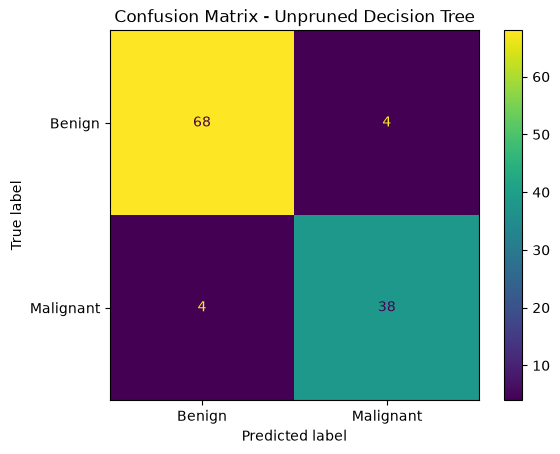

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_test_pred, labels=["B", "M"])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

disp.plot()
plt.title("Confusion Matrix - Unpruned Decision Tree")
plt.show()

###  Visualize the Decision Tree

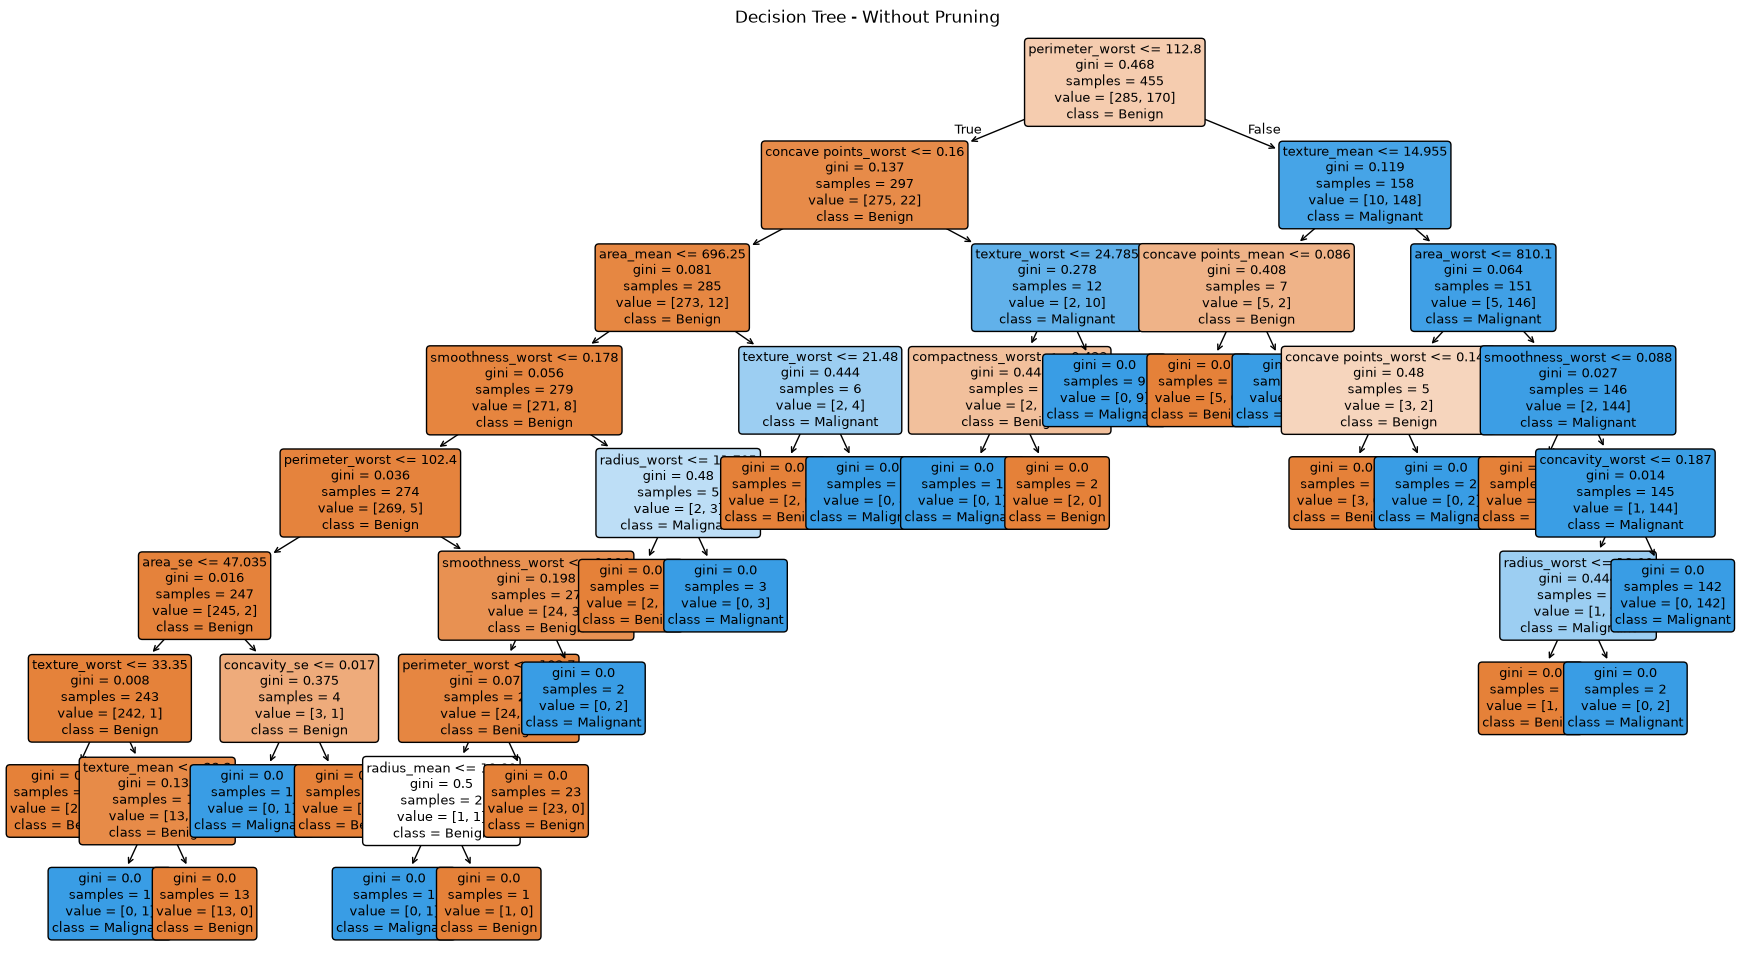

In [27]:
plt.figure(figsize=(22, 12))

plot_tree(
    dt_unpruned,
    feature_names=df.drop(
        columns=["id", "diagnosis", "Unnamed: 32"],
        errors="ignore"
    ).columns,
    class_names=["Benign", "Malignant"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree - Without Pruning")
plt.show()

#### VISUALIZE TEXT REPRESENTATION

In [29]:
from sklearn.tree import export_text

text_representation = export_text(
    dt_unpruned,
    feature_names=list(df.drop(
        columns=["id", "diagnosis", "Unnamed: 32"],
        errors="ignore"
    ).columns)
)

print(text_representation)

|--- perimeter_worst <= 112.80
|   |--- concave points_worst <= 0.16
|   |   |--- area_mean <= 696.25
|   |   |   |--- smoothness_worst <= 0.18
|   |   |   |   |--- perimeter_worst <= 102.40
|   |   |   |   |   |--- area_se <= 47.03
|   |   |   |   |   |   |--- texture_worst <= 33.35
|   |   |   |   |   |   |   |--- class: B
|   |   |   |   |   |   |--- texture_worst >  33.35
|   |   |   |   |   |   |   |--- texture_mean <= 23.20
|   |   |   |   |   |   |   |   |--- class: M
|   |   |   |   |   |   |   |--- texture_mean >  23.20
|   |   |   |   |   |   |   |   |--- class: B
|   |   |   |   |   |--- area_se >  47.03
|   |   |   |   |   |   |--- concavity_se <= 0.02
|   |   |   |   |   |   |   |--- class: M
|   |   |   |   |   |   |--- concavity_se >  0.02
|   |   |   |   |   |   |   |--- class: B
|   |   |   |   |--- perimeter_worst >  102.40
|   |   |   |   |   |--- smoothness_worst <= 0.14
|   |   |   |   |   |   |--- perimeter_worst <= 102.70
|   |   |   |   |   |   |   |--- radius_m

## Hyperparameter Tuning (Manual Coding)
## Control Tree Depth

In [30]:
depths = [1, 2, 3, 4, 5, 6, 7, 8]

results = []

for depth in depths:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    results.append({
        "Max Depth": depth,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Precision": precision_score(y_test, test_pred, pos_label="M"),
        "Recall": recall_score(y_test, test_pred, pos_label="M"),
        "F1 Score": f1_score(y_test, test_pred, pos_label="M")
    })

depth_results = pd.DataFrame(results)

depth_results

,Max Depth,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score
0,1,0.929670,0.877193,0.937500,0.714286,0.810811
1,2,0.953846,0.921053,0.971429,0.809524,0.883117
2,3,0.967033,0.903509,0.942857,0.785714,0.857143
3,4,0.982418,0.912281,0.944444,0.809524,0.871795
4,5,0.986813,0.921053,0.945946,0.833333,0.886076
5,6,0.993407,0.921053,0.923077,0.857143,0.888889
6,7,0.995604,0.938596,0.948718,0.880952,0.913580
7,8,1.000000,0.929825,0.904762,0.904762,0.904762


### Plot Training vs Testing Accuracy

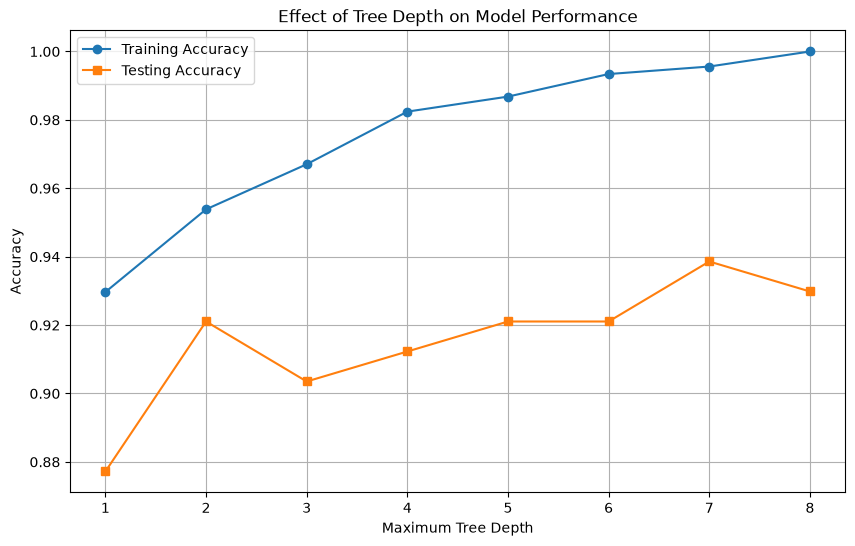

In [31]:
plt.figure(figsize=(10, 6))

plt.plot(
    depth_results["Max Depth"],
    depth_results["Train Accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depth_results["Max Depth"],
    depth_results["Test Accuracy"],
    marker="s",
    label="Testing Accuracy"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Effect of Tree Depth on Model Performance")
plt.legend()
plt.grid(True)
plt.show()

## Effect of Maximum Depth

The `max_depth` parameter controls how deep the tree is allowed to grow.

### Small depth

A very small tree may be too simple to capture the relationship between the
features and target.

This is called **underfitting**.

### Large depth

A very deep tree can learn highly specific patterns in the training dataset.

This may result in:

- Very high training accuracy
- Lower testing accuracy

This is an indication of **overfitting**.

### Appropriate depth

An appropriate depth provides a balance between model complexity and
generalization.

### Cost-Complexity Pruning

Decision Trees in scikit-learn support cost-complexity pruning using the parameter:

In [33]:
path = dt_unpruned.cost_complexity_pruning_path(X_train, y_train)

ccp_alphas = path.ccp_alphas

print("CCP Alpha Values:")
print(ccp_alphas)

CCP Alpha Values:
[0.         0.00210989 0.00218001 0.00218264 0.0029304  0.00430549
 0.00431858 0.0043956  0.00527473 0.00527473 0.00586081 0.00627943
 0.00730477 0.00730484 0.01050899 0.01364431 0.03168777 0.33734531]


In [34]:
# Obtain pruning path
path = dt_unpruned.cost_complexity_pruning_path(
    X_train,
    y_train
)

ccp_alphas = path.ccp_alphas

print("Number of candidate alpha values:", len(ccp_alphas))
print("First few alpha values:")
print(ccp_alphas[:10])

Number of candidate alpha values: 18
First few alpha values:
[0.         0.00210989 0.00218001 0.00218264 0.0029304  0.00430549
 0.00431858 0.0043956  0.00527473 0.00527473]


## Cost-Complexity Pruning

Cost-complexity pruning removes branches that provide relatively little
improvement in classification performance.

The parameter `ccp_alpha` controls the amount of pruning.

- `ccp_alpha = 0` → essentially no cost-complexity pruning
- Small `ccp_alpha` → little pruning
- Larger `ccp_alpha` → stronger pruning

Increasing `ccp_alpha` generally produces a smaller and simpler tree.

## Train Trees with Different Pruning Levels

In [35]:
pruning_results = []

# Ignore the final alpha because it produces a tree with only one node
for alpha in ccp_alphas[:-1]:

    model = DecisionTreeClassifier(
        random_state=42,
        ccp_alpha=alpha
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    pruning_results.append({
        "ccp_alpha": alpha,
        "Depth": model.get_depth(),
        "Leaves": model.get_n_leaves(),
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Precision": precision_score(y_test, test_pred, pos_label="M"),
        "Recall": recall_score(y_test, test_pred, pos_label="M"),
        "F1 Score": f1_score(y_test, test_pred, pos_label="M")
    })

pruning_results = pd.DataFrame(pruning_results)

pruning_results.head()

,ccp_alpha,Depth,Leaves,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score
0,0.000000,8,24,1.000000,0.929825,0.904762,0.904762,0.904762
1,0.002110,8,22,0.997802,0.929825,0.904762,0.904762,0.904762
2,0.002180,6,18,0.993407,0.947368,0.950000,0.904762,0.926829
3,0.002183,6,16,0.991209,0.947368,0.950000,0.904762,0.926829
4,0.002930,6,15,0.989011,0.947368,0.950000,0.904762,0.926829


## Select a Pruned Tree

In [36]:
# Select the model having the highest test accuracy
best_row = pruning_results.loc[
    pruning_results["Test Accuracy"].idxmax()
]

best_alpha = best_row["ccp_alpha"]

print("Selected ccp_alpha:", best_alpha)
print("Test Accuracy:", best_row["Test Accuracy"])
print("Tree Depth:", best_row["Depth"])
print("Number of Leaves:", best_row["Leaves"])

Selected ccp_alpha: 0.0021800062285892226
Test Accuracy: 0.9473684210526315
Tree Depth: 6.0
Number of Leaves: 18.0


In [37]:
# Train final pruned tree
dt_pruned = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=best_alpha
)

dt_pruned.fit(X_train, y_train)

y_pruned_pred = dt_pruned.predict(X_test)

print(classification_report(y_test, y_pruned_pred))

              precision    recall  f1-score   support

           B       0.95      0.97      0.96        72
           M       0.95      0.90      0.93        42

    accuracy                           0.95       114
   macro avg       0.95      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



## Visualize the Pruned Tree

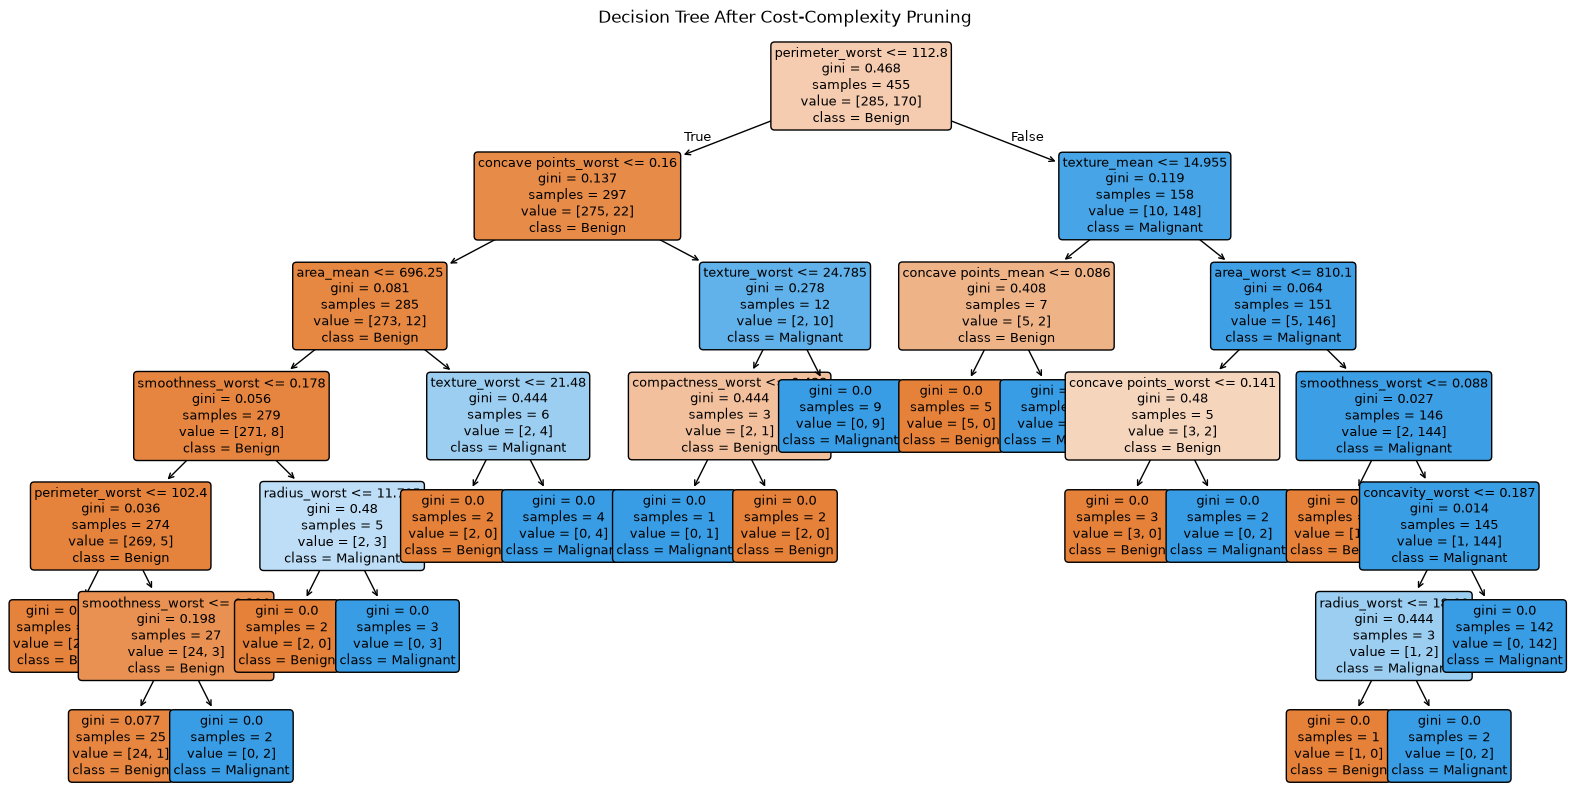

In [38]:
plt.figure(figsize=(20, 10))

plot_tree(
    dt_pruned,
    feature_names=df.drop(
        columns=["id", "diagnosis", "Unnamed: 32"],
        errors="ignore"
    ).columns,
    class_names=["Benign", "Malignant"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree After Cost-Complexity Pruning")
plt.show()

## Pruned Tree

The pruned tree should generally contain fewer branches than the original
tree.

Benefits of pruning include:

- Lower model complexity
- Better interpretability
- Reduced sensitivity to noise
- Potentially better generalization
- Smaller visualization

Pruning does not necessarily mean that test accuracy will always increase.
The appropriate amount of pruning should be determined using validation
data or cross-validation rather than simply assuming that the smallest tree
is the best tree.

### Compare Unpruned and Pruned Trees

In [ ]:
comparison = pd.DataFrame({
    "Model": [
        "Unpruned Tree",
        "Pruned Tree"
    ],

    "Train Accuracy": [
        accuracy_score(y_train, dt_unpruned.predict(X_train)),
        accuracy_score(y_train, dt_pruned.predict(X_train))
    ],

    "Test Accuracy": [
        accuracy_score(y_test, dt_unpruned.predict(X_test)),
        accuracy_score(y_test, dt_pruned.predict(X_test))
    ],

    "Precision": [
        precision_score(y_test, dt_unpruned.predict(X_test)),
        precision_score(y_test, dt_pruned.predict(X_test))
    ],

    "Recall": [
        recall_score(y_test, dt_unpruned.predict(X_test)),
        recall_score(y_test, dt_pruned.predict(X_test))
    ],

    "F1 Score": [
        f1_score(y_test, dt_unpruned.predict(X_test)),
        f1_score(y_test, dt_pruned.predict(X_test))
    ],

    "Depth": [
        dt_unpruned.get_depth(),
        dt_pruned.get_depth()
    ],

    "Leaves": [
        dt_unpruned.get_n_leaves(),
        dt_pruned.get_n_leaves()
    ]
})

comparison

# Demonstrate Overfitting Using Synthetic Data

In [24]:
from sklearn.datasets import make_moons

# Generate synthetic data
X_syn, y_syn = make_moons(
    n_samples=500,
    noise=0.25,
    random_state=42
)

# Split the synthetic data
X_syn_train, X_syn_test, y_syn_train, y_syn_test = train_test_split(
    X_syn,
    y_syn,
    test_size=0.30,
    random_state=42,
    stratify=y_syn
)

print("Training samples:", len(X_syn_train))
print("Testing samples:", len(X_syn_test))

Training samples: 350
Testing samples: 150


## Visualize Synthetic Dataset

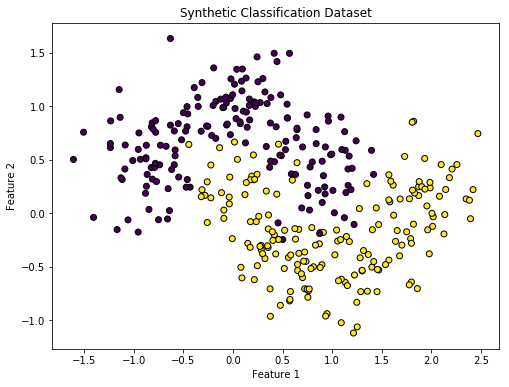

In [25]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_syn_train[:, 0],
    X_syn_train[:, 1],
    c=y_syn_train,
    edgecolor="k"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Synthetic Classification Dataset")
plt.show()

### Train Shallow and Deep Trees

In [30]:
# Shallow tree
shallow_tree = DecisionTreeClassifier(
    max_depth=2,
    random_state=42
)

# Deep tree
deep_tree = DecisionTreeClassifier(
    max_depth=None,
    random_state=42
)

shallow_tree.fit(X_syn_train, y_syn_train)
deep_tree.fit(X_syn_train, y_syn_train)

# Predictions
shallow_train_pred = shallow_tree.predict(X_syn_train)
shallow_test_pred = shallow_tree.predict(X_syn_test)

deep_train_pred = deep_tree.predict(X_syn_train)
deep_test_pred = deep_tree.predict(X_syn_test)

print("Shallow Tree")
print("----------------")
print("Training Accuracy:",
      accuracy_score(y_syn_train, shallow_train_pred))
print("Testing Accuracy:",
      accuracy_score(y_syn_test, shallow_test_pred))

print("\nDeep Tree")
print("----------------")
print("Training Accuracy:",
      accuracy_score(y_syn_train, deep_train_pred))
print("Testing Accuracy:",
      accuracy_score(y_syn_test, deep_test_pred))

Shallow Tree
----------------
Training Accuracy: 0.9114285714285715
Testing Accuracy: 0.8933333333333333

Deep Tree
----------------
Training Accuracy: 1.0
Testing Accuracy: 0.9466666666666667


### Demonstrate Overfitting with Different Depths

In [31]:
synthetic_results = []

for depth in range(1, 16):

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_syn_train, y_syn_train)

    train_accuracy = model.score(
        X_syn_train,
        y_syn_train
    )

    test_accuracy = model.score(
        X_syn_test,
        y_syn_test
    )

    synthetic_results.append({
        "Depth": depth,
        "Training Accuracy": train_accuracy,
        "Testing Accuracy": test_accuracy
    })

synthetic_results = pd.DataFrame(synthetic_results)

synthetic_results

,Depth,Testing Accuracy,Training Accuracy
0,1,0.806667,0.842857
1,2,0.893333,0.911429
2,3,0.893333,0.911429
3,4,0.893333,0.911429
4,5,0.946667,0.974286
5,6,0.953333,0.982857
6,7,0.953333,0.991429
7,8,0.946667,1.000000
8,9,0.946667,1.000000
9,10,0.946667,1.000000


### Plot Overfitting

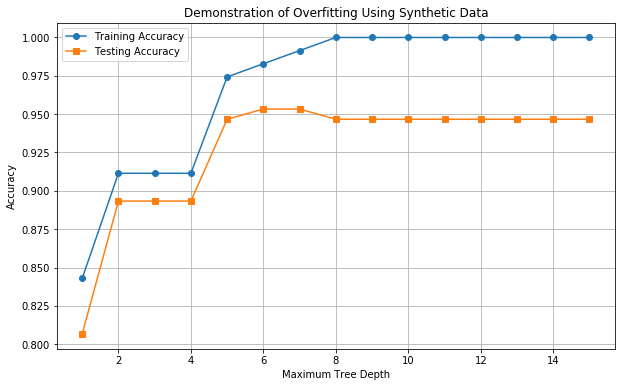

In [32]:
plt.figure(figsize=(10, 6))

plt.plot(
    synthetic_results["Depth"],
    synthetic_results["Training Accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    synthetic_results["Depth"],
    synthetic_results["Testing Accuracy"],
    marker="s",
    label="Testing Accuracy"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Demonstration of Overfitting Using Synthetic Data")
plt.legend()
plt.grid(True)
plt.show()

# Understanding Overfitting

The synthetic experiment demonstrates the relationship between tree complexity
and generalization.

When the tree depth increases:

1. The tree becomes more complex.
2. Training accuracy generally increases.
3. The tree starts fitting very specific training observations.
4. Testing accuracy may stop improving or decrease.

The gap between training and testing accuracy is an important indication of
overfitting.

For example:

    Training Accuracy = 100%
    Testing Accuracy  = 85%

indicates that the model has learned the training data extremely well but
does not generalize equally well to unseen data.

This is why controlling model complexity is important.

## Visualize Shallow vs Deep Tree

In [33]:
plt.figure(figsize=(12, 8))

plot_tree(
    shallow_tree,
    filled=True,
    rounded=True,
    feature_names=["Feature 1", "Feature 2"],
    class_names=["Class 0", "Class 1"]
)

plt.title("Shallow Decision Tree")
plt.show()

NameError: name 'plot_tree' is not defined

<Figure size 864x576 with 0 Axes>

In [ ]:
plt.figure(figsize=(20, 12))

plot_tree(
    deep_tree,
    filled=True,
    rounded=True,
    feature_names=["Feature 1", "Feature 2"],
    class_names=["Class 0", "Class 1"],
    fontsize=8
)

plt.title("Deep Decision Tree")
plt.show()

# Final Analysis
# Final Analysis

## 1. Without Pruning

The unrestricted Decision Tree can achieve very high training accuracy.
However, unrestricted growth increases model complexity and can cause
overfitting.

For the Bill Authentication dataset, the unpruned tree reached approximately:

- Training Accuracy: 100%
- Testing Accuracy: 99.27%

The small difference between training and testing accuracy indicates that
the tree generalizes well on this particular train-test split despite being
fully grown.

---

## 2. Depth Control

The `max_depth` parameter limits the number of levels in the tree.

A very small value may cause underfitting because the model is too simple.

Increasing the depth allows the tree to learn more complex relationships.

However, after a certain point, additional complexity may not improve
performance on unseen data.

---

## 3. Pruning

Cost-complexity pruning uses the `ccp_alpha` parameter.

Pruning removes branches that add relatively little value to the model.

Advantages:

- Reduces tree size
- Improves interpretability
- Can reduce overfitting
- Can improve generalization

---

## 4. Synthetic Data

The synthetic experiment clearly demonstrates that a highly flexible tree
can fit the training data extremely well.

A deep tree may achieve nearly 100% training accuracy while its test
accuracy does not increase by the same amount.

This difference illustrates overfitting.

---

## 5. Overall Conclusion

Decision Trees are powerful and interpretable classification algorithms.

However, unrestricted tree growth can result in unnecessary model complexity.

Two important techniques for controlling complexity are:

1. **Depth control**
   - `max_depth`

2. **Cost-complexity pruning**
   - `ccp_alpha`

The appropriate tree should be selected based on validation/test performance
and model complexity rather than training accuracy alone.